# Assignment 2
#### Casey Elizabeth Gilbert

In [80]:
# import a bunch of stuff
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
from matplotlib import rc
import time
import random
import math
from collections import Counter

## Question 1

#### Question 1a

In [95]:
def grow_barabasi_albert_net(N, m):
    """
    This function creates a scale-free network using barabasi-albert model.

    It loops through and adds the proper amount of nodes (specified as param).
    For each node, it connects via m links to existing nodes. 

    NOTES:
    Adds links with preferential attachment, the preferential attachment comes from choosing a random edge.
    So a node with twice as many edges is twice as likely to have an edge chosen.
    Because degree = edge count * 2, th probability for each node is then halved
    This is taken care of when we randomly select one of the edge's nodes.
    
    This doesn't allow self loops, and isn't exactly LCD, but it is computationally cleaner,
    and I think should create scale-free networks.

    @param N (int): The number of nodes
    @param m (int): Number of edges formed for each new node

    @return the scale-free network
    @return an array of degree sequences at N^x
    """

    degree_sequences = []

    simple_graph = nx.complete_graph(4)

    start_graph = nx.MultiGraph(simple_graph)
     
    t = 5

    # get our order of magnitude so we know what to print
    o_of_m = int(math.log10(N))

    degree_sequences_vals = []
    if (o_of_m > 1):
        for i in range(2,o_of_m + 1):
            degree_sequences_vals.append(10**i)
    print(degree_sequences_vals)
    while t < N:
        t = t + 1

        # add node
        start_graph.add_node(t)

        # we don't want to accidentally select the new node's edge,
        # so we get the edge list ahead of time
        edge_list = list(start_graph.edges) 

        # Now add the m edges
        for i in range(0,m):
            # get random edge
            chosen_edge = edge_list[random.randint(0,len(edge_list)-1)]
            #print(f"chosen_edge: {chosen_edge}")

            #randomly choose one edge of that link
            chosen_node = chosen_edge[random.randint(0,1)]
            #print(f"Chosen node: {chosen_node}")

            # attach the new edge 
            start_graph.add_edge(t, chosen_node)

        if t in degree_sequences_vals:
            degree_seq = np.array(list(dict(start_graph.degree()).values()))
            degree_sequences.append(degree_seq)


    return start_graph, degree_sequences
    

[100]


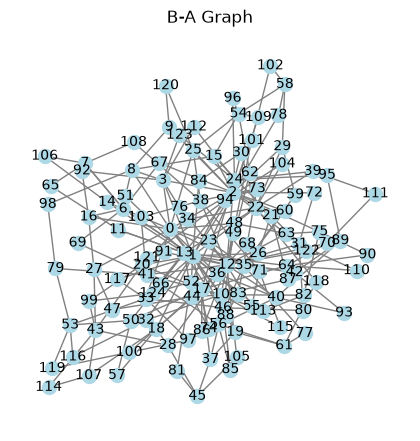

In [96]:
N = 10**4
m = 4
# Just test it with smaller numbers to see what's up
G, degree_dists = grow_barabasi_albert_net(124,2)

plt.figure(figsize=(4, 4))
nx.draw(G, with_labels=True, node_color='lightblue', edge_color='gray', node_size=100, font_size=10)
plt.title("B-A Graph")
plt.show()

In [ ]:
N = 10**4
m = 4
# Just test it with smaller numbers to see what's up
G, degree_dists = grow_barabasi_albert_net(N,m)

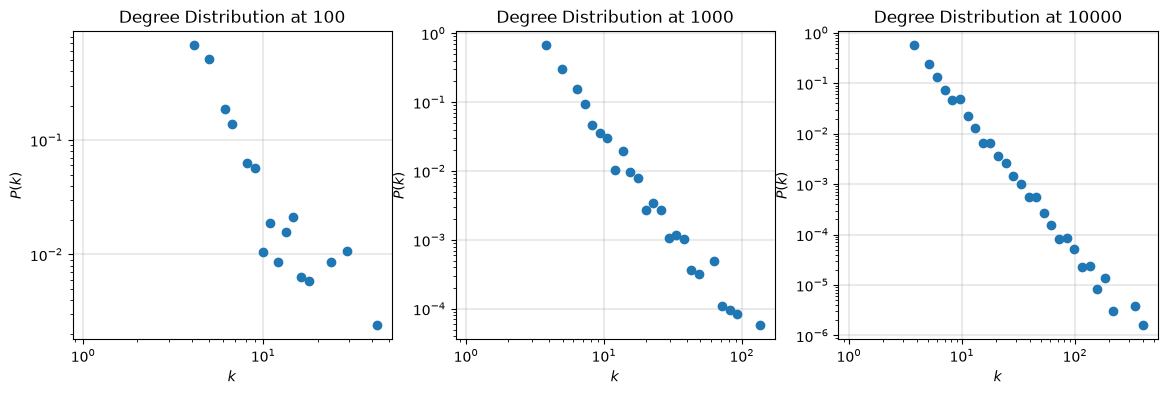

In [110]:
fig, ax = plt.subplots(1,len(degree_dists),figsize=(14,4),dpi=100)

for i in range(0, len(degree_dists)):
    # get nice binned distributions 
    deg_vals = degree_dists[i]
    deg_bins = np.logspace(0, np.log10(np.max(deg_vals)+1), num=40)
    probs, _ = np.histogram(deg_vals, bins=deg_bins, density=True)
    final_bins = deg_bins[1:] - np.diff(deg_bins)/2.0

    # plot that puppy
    ax[i].loglog(final_bins, probs, marker='o',lw=0)
    ax[i].set_xlabel(r"$k$", fontsize='medium')
    ax[i].set_ylabel(r"$P(k)$", fontsize='medium')
    ax[i].grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')
    ax[i].set_title(f'Degree Distribution at {10**(i+2)}', fontsize='large')

plt.show()

In [91]:
Counter(deg_vals)

Counter({np.int64(2): 50,
         np.int64(3): 16,
         np.int64(4): 11,
         np.int64(5): 7,
         np.int64(18): 2,
         np.int64(14): 2,
         np.int64(10): 2,
         np.int64(11): 2,
         np.int64(6): 2,
         np.int64(7): 1,
         np.int64(13): 1,
         np.int64(9): 1,
         np.int64(15): 1,
         np.int64(1): 1})

In [94]:
deg_vals


array([18, 14, 18, 14, 10,  7, 11, 13, 10,  6,  6,  9,  5,  2,  5, 15,  5,
        4,  2,  5, 11,  2,  2,  4,  4,  3,  4,  3,  5,  2,  3,  4,  3,  2,
        2,  2,  2,  3,  3,  4,  3,  5,  2,  5,  2,  4,  2,  3,  3,  3,  4,
        2,  2,  4,  2,  3,  2,  3,  3,  4,  2,  2,  1,  2,  2,  2,  3,  2,
        2,  2,  4,  2,  2,  2,  2,  2,  2,  3,  2,  2,  2,  2,  2,  2,  2,
        3,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2])